# Task 04: Sentiment Analysis Using NLP

## Project Overview

This project aims to build a Natural Language Processing (NLP) system that classifies customer reviews into positive and negative sentiments.

The project uses text preprocessing techniques and TF-IDF vectorization to transform textual data into numerical features.

Two machine learning classifiers, Multinomial Naive Bayes and Logistic Regression, will be trained and compared.

## Objectives

- Load and explore the sentiment reviews dataset.
- Clean and preprocess textual data.
- Remove HTML tags, punctuation, and stopwords.
- Apply lemmatization.
- Convert text into numerical features using TF-IDF.
- Train Multinomial Naive Bayes and Logistic Regression.
- Evaluate and compare model performance.
- Build an interactive sentiment prediction function.

## Models

1. Multinomial Naive Bayes
2. Logistic Regression

## Evaluation Metrics

- Accuracy
- Precision
- Recall
- F1-Score
- Confusion Matrix

## 1. Import Libraries

Import the required libraries for data manipulation, text preprocessing, feature extraction, model training, and evaluation.

In [1]:

# Data Manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Text Processing
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Feature Extraction
from sklearn.feature_extraction.text import TfidfVectorizer

# Data Splitting
from sklearn.model_selection import train_test_split

# Machine Learning Models
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    roc_auc_score
)

# Settings
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

print("All libraries imported successfully!")


All libraries imported successfully!


## 2. Download NLTK Resources

Download the language resources required for stopword removal and lemmatization.

These resources help us clean and normalize English review text before feature extraction.

In [2]:

# Download required NLTK resources
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

print("NLTK resources downloaded successfully!")


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\DELL\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\DELL\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\DELL\AppData\Roaming\nltk_data...


NLTK resources downloaded successfully!


## 3. Load Dataset

Load the customer sentiment reviews dataset provided by Datheon.

Inspect the dataset structure and display sample records to identify the text and sentiment columns.

In [3]:

# Load the downloaded dataset
df = pd.read_csv("IMDB Dataset.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset Shape: (50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


## 4. Initial Dataset Inspection

Inspect the dataset columns, data types, missing values, and basic statistics.

This step helps identify the review text column and the sentiment target column before preprocessing.

In [4]:

# Dataset information
df.info()
print()
print("__________________________________")

# Column names
print("\nDataset Columns:")
print(df.columns.tolist())
print()
print("__________________________________")

# Missing values
print("\nMissing Values:")
display(df.isnull().sum())
print()
print("__________________________________")

# Duplicate records
print("\nDuplicate Records:", df.duplicated().sum())
print()
print("__________________________________")

# Sample records
display(df.sample(min(5, len(df)), random_state=42))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB

__________________________________

Dataset Columns:
['review', 'sentiment']

__________________________________

Missing Values:


review       0
sentiment    0
dtype: int64


__________________________________

Duplicate Records: 418

__________________________________


,review,sentiment
33553,I really liked this Summerslam due to the look...,positive
9427,Not many television shows appeal to quite as m...,positive
199,The film quickly gets to a major chase scene w...,negative
12447,Jane Austen would definitely approve of this o...,positive
39489,Expectations were somewhat high for me when I ...,negative



## 5. Data Cleaning

Prepare the dataset before text preprocessing.

- Remove missing reviews.
- Remove duplicate reviews.
- Normalize sentiment labels.
- Keep only positive and negative sentiment records.


In [5]:

# Remove missing values
df = df.dropna(subset=["review", "sentiment"])

# Remove duplicate reviews
df = df.drop_duplicates(subset=["review"])

# Normalize sentiment labels
df["sentiment"] = df["sentiment"].str.lower().str.strip()

# Keep only binary sentiment classes
df = df[df["sentiment"].isin(["positive", "negative"])].copy()

# Reset index
df.reset_index(drop=True, inplace=True)

print("Cleaned Dataset Shape:", df.shape)
print("\nSentiment Distribution:")
display(df["sentiment"].value_counts())


Cleaned Dataset Shape: (49582, 2)

Sentiment Distribution:


sentiment
positive    24884
negative    24698
Name: count, dtype: int64


## 6. Sentiment Distribution Visualization

Visualize the number of positive and negative reviews to understand the class distribution.


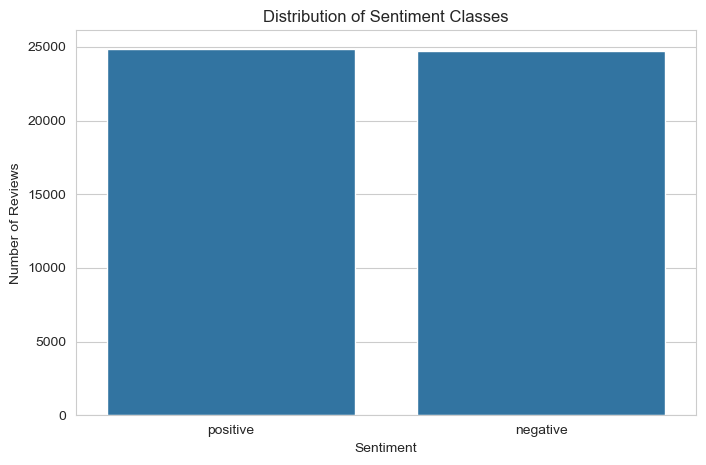

In [6]:

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="sentiment"
)

plt.title("Distribution of Sentiment Classes")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()



## 7. Text Preprocessing

Create a text cleaning function to:

- Convert text to lowercase.
- Remove HTML tags.
- Remove URLs.
- Remove punctuation and special characters.
- Remove English stopwords while preserving important negation words.
- Apply WordNet lemmatization.
- Normalize extra whitespace.

Preserving negation words such as "not" and "no" is important because they can change the meaning of a review.


In [7]:

# Initialize stopwords and lemmatizer
stop_words = set(stopwords.words("english"))

# Preserve negation words
negation_words = {"no", "not", "nor", "never"}
stop_words = stop_words - negation_words

lemmatizer = WordNetLemmatizer()


def clean_text(text):
    # Convert to string and lowercase
    text = str(text).lower()

    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", " ", text)

    # Keep alphabetic characters and spaces
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # Tokenization
    words = text.split()

    # Stopword removal and lemmatization
    cleaned_words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word not in stop_words
    ]

    return " ".join(cleaned_words)


print("Text preprocessing function created successfully!")


Text preprocessing function created successfully!



## 8. Apply Text Preprocessing

Apply the cleaning function to all movie reviews and compare the original and processed text.


In [8]:

df["cleaned_review"] = df["review"].apply(clean_text)

print("Text preprocessing completed!")

print("\nOriginal Review:")
print(df["review"].iloc[0][:500])

print("\nCleaned Review:")
print(df["cleaned_review"].iloc[0][:500])


Text preprocessing completed!

Original Review:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ

Cleaned Review:
one reviewer mentioned watching oz episode hooked right exactly happened first thing struck oz brutality unflinching scene violence set right word go trust not show faint hearted timid show pull no punch regard drug sex violence hardcore classic use word called oz nickname given oswald maximum security state penitentary focus mainly emerald city experimental section prison cell glass front face inwards privacy not high agenda em c


## 9. TF-IDF Feature Extraction

Convert cleaned text into numerical feature vectors using TfidfVectorizer.

The vectorizer uses a maximum of 5,000 features and unigram/bigram representations.

TF-IDF helps assign higher importance to informative words while reducing the influence of very common terms.


In [9]:

# Define input and target
X = df["cleaned_review"]
y = df["sentiment"].map({
    "negative": 0,
    "positive": 1
})

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

# TF-IDF vectorization
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("\nTF-IDF Transformation Completed!")
print("Training Matrix Shape:", X_train_tfidf.shape)
print("Testing Matrix Shape:", X_test_tfidf.shape)


Training Samples: 39665
Testing Samples: 9917

TF-IDF Transformation Completed!
Training Matrix Shape: (39665, 5000)
Testing Matrix Shape: (9917, 5000)



## 10. Train Multinomial Naive Bayes

Train a Multinomial Naive Bayes classifier using the TF-IDF training features.

This model is commonly used for text classification because it is computationally efficient and works with non-negative feature values.


In [10]:

nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

nb_predictions = nb_model.predict(X_test_tfidf)
nb_probabilities = nb_model.predict_proba(X_test_tfidf)[:, 1]

print("Multinomial Naive Bayes training completed!")


Multinomial Naive Bayes training completed!



## 11. Train Logistic Regression

Train a Logistic Regression classifier using the same TF-IDF features.

Using the same training and testing data allows a fair comparison between both models.


In [11]:

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_tfidf, y_train)

lr_predictions = lr_model.predict(X_test_tfidf)
lr_probabilities = lr_model.predict_proba(X_test_tfidf)[:, 1]

print("Logistic Regression training completed!")


Logistic Regression training completed!



## 12. Model Evaluation

Evaluate both classifiers using Accuracy, Precision, Recall, and F1-Score.

These metrics provide a comprehensive comparison of the models' classification performance.


In [12]:

def evaluate_model(y_true, y_pred, model_name):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-Score": f1_score(y_true, y_pred)
    }


results = pd.DataFrame([
    evaluate_model(y_test, nb_predictions, "Multinomial Naive Bayes"),
    evaluate_model(y_test, lr_predictions, "Logistic Regression")
])

display(results.round(4))


,Model,Accuracy,Precision,Recall,F1-Score
0,Multinomial Naive Bayes,0.8633,0.8545,0.8768,0.8655
1,Logistic Regression,0.8917,0.8838,0.9030,0.8933



## 13. Classification Reports

Display detailed classification reports for both models, including class-level precision, recall, and F1-score.


In [13]:

print("Multinomial Naive Bayes Report:")
print(classification_report(
    y_test,
    nb_predictions,
    target_names=["Negative", "Positive"]
))

print("\nLogistic Regression Report:")
print(classification_report(
    y_test,
    lr_predictions,
    target_names=["Negative", "Positive"]
))


Multinomial Naive Bayes Report:
              precision    recall  f1-score   support

    Negative       0.87      0.85      0.86      4940
    Positive       0.85      0.88      0.87      4977

    accuracy                           0.86      9917
   macro avg       0.86      0.86      0.86      9917
weighted avg       0.86      0.86      0.86      9917


Logistic Regression Report:
              precision    recall  f1-score   support

    Negative       0.90      0.88      0.89      4940
    Positive       0.88      0.90      0.89      4977

    accuracy                           0.89      9917
   macro avg       0.89      0.89      0.89      9917
weighted avg       0.89      0.89      0.89      9917




## 14. Confusion Matrix Comparison

Visualize the confusion matrices to examine correct and incorrect predictions for each sentiment class.


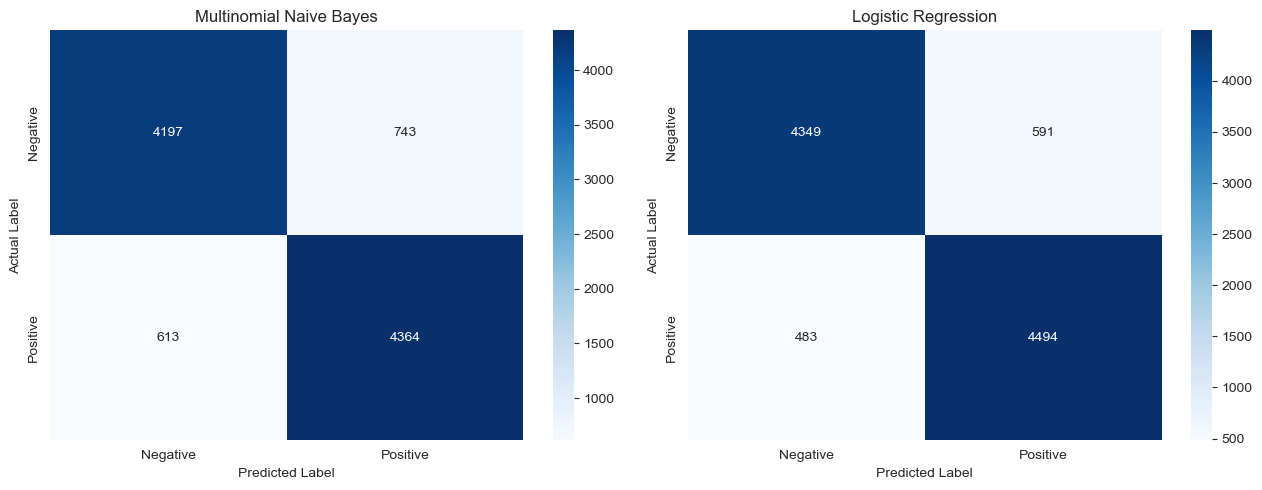

In [14]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

models = [
    ("Multinomial Naive Bayes", nb_predictions),
    ("Logistic Regression", lr_predictions)
]

for ax, (name, predictions) in zip(axes, models):
    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Negative", "Positive"],
        yticklabels=["Negative", "Positive"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()



## 15. ROC Curve and AUC Score

Compare both classifiers using ROC curves and their Area Under the Curve (AUC) scores.

A higher AUC indicates better separation between positive and negative sentiment classes.


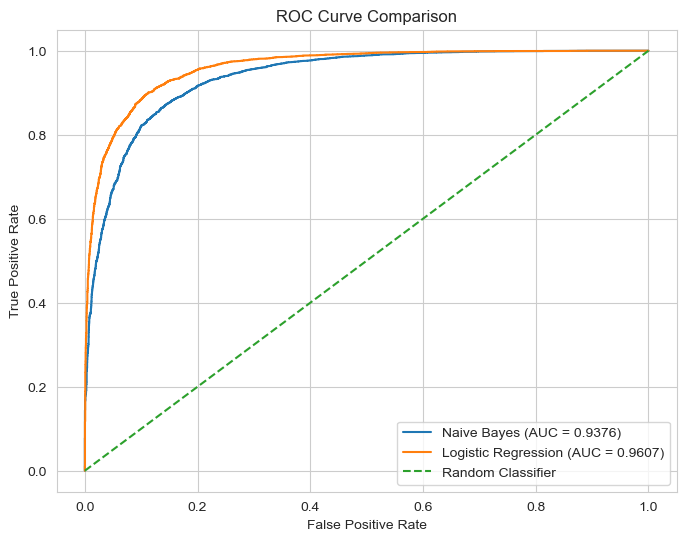

Naive Bayes AUC: 0.9376
Logistic Regression AUC: 0.9607


In [15]:

nb_auc = roc_auc_score(y_test, nb_probabilities)
lr_auc = roc_auc_score(y_test, lr_probabilities)

nb_fpr, nb_tpr, _ = roc_curve(y_test, nb_probabilities)
lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_probabilities)

plt.figure(figsize=(8, 6))

plt.plot(
    nb_fpr, nb_tpr,
    label=f"Naive Bayes (AUC = {nb_auc:.4f})"
)

plt.plot(
    lr_fpr, lr_tpr,
    label=f"Logistic Regression (AUC = {lr_auc:.4f})"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

print("Naive Bayes AUC:", round(nb_auc, 4))
print("Logistic Regression AUC:", round(lr_auc, 4))



## 16. Model Performance Comparison

Visualize the evaluation metrics to compare the strengths and weaknesses of both classifiers.


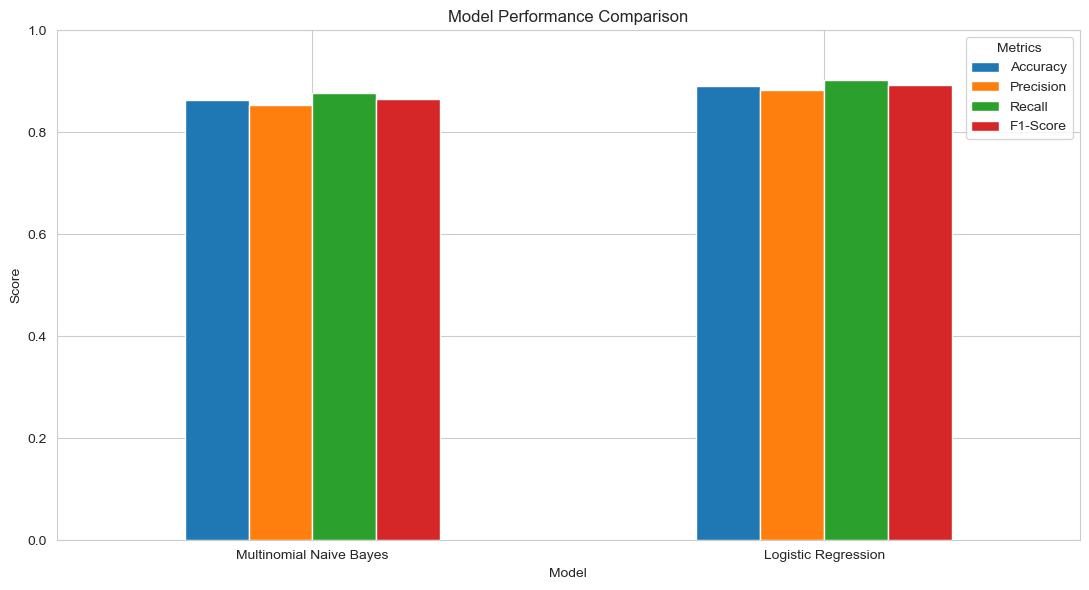

In [16]:

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

results_plot = results.set_index("Model")[metrics]

results_plot.plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 1),
    rot=0
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.legend(title="Metrics")
plt.tight_layout()
plt.show()



## 17. Interactive Sentiment Prediction

Create a reusable `predict_sentiment()` function.

The function accepts a new review, applies the same preprocessing and TF-IDF transformation, and predicts whether the sentiment is positive or negative.

The Logistic Regression model is used as the default prediction model. The user can also select Naive Bayes.


In [17]:

def predict_sentiment(review, model_name="Logistic Regression"):
    # Clean input review
    cleaned_review = clean_text(review)

    # Convert review into TF-IDF features
    review_vector = tfidf.transform([cleaned_review])

    # Select model
    if model_name == "Naive Bayes":
        model = nb_model
    else:
        model = lr_model

    # Predict sentiment
    prediction = model.predict(review_vector)[0]
    probability = model.predict_proba(review_vector)[0]

    sentiment = "Positive" if prediction == 1 else "Negative"
    confidence = probability[prediction] * 100

    print("Review:", review)
    print("Predicted Sentiment:", sentiment)
    print(f"Confidence: {confidence:.2f}%")

    return sentiment


print("Sentiment prediction function created successfully!")


Sentiment prediction function created successfully!



## 18. Test Custom User Reviews

Test the trained model using custom positive and negative movie review examples.

This demonstrates how the model can classify new text that was not included in the training dataset.


In [18]:

test_reviews = [
    "This movie was absolutely wonderful. I loved every minute of it.",
    "The film was terrible, boring, and a complete waste of time.",
    "The acting was excellent and the story was very engaging.",
    "I did not enjoy this movie. It was disappointing and poorly written."
]

for review in test_reviews:
    print("-" * 70)
    predict_sentiment(review)


----------------------------------------------------------------------
Review: This movie was absolutely wonderful. I loved every minute of it.
Predicted Sentiment: Positive
Confidence: 93.00%
----------------------------------------------------------------------
Review: The film was terrible, boring, and a complete waste of time.
Predicted Sentiment: Negative
Confidence: 99.99%
----------------------------------------------------------------------
Review: The acting was excellent and the story was very engaging.
Predicted Sentiment: Positive
Confidence: 95.95%
----------------------------------------------------------------------
Review: I did not enjoy this movie. It was disappointing and poorly written.
Predicted Sentiment: Negative
Confidence: 96.77%



## 19. Interactive User Input

Allow users to enter their own movie review and select a model to predict its sentiment.


In [ ]:

user_review = input("Enter a movie review: ")

print("\nChoose a model:")
print("1. Logistic Regression")
print("2. Naive Bayes")

choice = input("Enter 1 or 2: ").strip()

selected_model = (
    "Naive Bayes" if choice == "2"
    else "Logistic Regression"
)

print("\nPrediction Result:")
predict_sentiment(user_review, selected_model)



## 20. Final Conclusion

This project successfully developed a Natural Language Processing (NLP) pipeline for binary sentiment classification using the IMDb 50K Movie Reviews dataset.

The project included text cleaning, lowercasing, HTML tag removal, stopword removal, lemmatization, and TF-IDF feature extraction with a maximum of 5,000 features.

Two machine learning classifiers were trained and evaluated: Multinomial Naive Bayes and Logistic Regression.

### Model Performance

| Metric | Multinomial Naive Bayes | Logistic Regression |
|---|---:|---:|
| Accuracy | 86.33% | 89.17% |
| Precision | 85.45% | 88.38% |
| Recall | 87.68% | 90.30% |
| F1-Score | 86.55% | 89.33% |
| ROC-AUC | 93.76% | 96.07% |

### Best Performing Model

Logistic Regression achieved the best overall performance, with:

- Accuracy: 89.17%
- Precision: 88.38%
- Recall: 90.30%
- F1-Score: 89.33%
- ROC-AUC: 96.07%

It outperformed Multinomial Naive Bayes across all reported evaluation metrics.

### Custom Prediction Results

The prediction helper was tested using four custom movie reviews.

All four predictions matched their intended sentiment:

- Positive review: correctly classified.
- Negative review: correctly classified.
- Positive review: correctly classified.
- Negative review: correctly classified.

### Dataset Note and Limitation

The original Datheon sample file contained only 10 product reviews and three sentiment labels: positive, negative, and neutral.

This sample was insufficient for reliable model training and evaluation. Therefore, the IMDb 50K Movie Reviews dataset was selected as the main dataset because it provides a substantially larger collection of positive and negative movie reviews.

The dataset change was made to support a more reliable binary sentiment classification experiment. The source and reason for this choice are documented as part of the project.

### Future Improvements

- Experiment with different TF-IDF configurations.
- Apply hyperparameter tuning.
- Test additional classification algorithms.
- Explore deep learning and transformer-based NLP models.
- Deploy the trained sentiment classifier as a web application.

Overall, Logistic Regression provided the strongest results and demonstrated effective performance in classifying positive and negative movie reviews.
